In [16]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

import pandas as pd

# Load data
file_path = "../0_DATA/COMPOUNDS/0_MOLECULES.csv"
df = pd.read_csv(file_path)

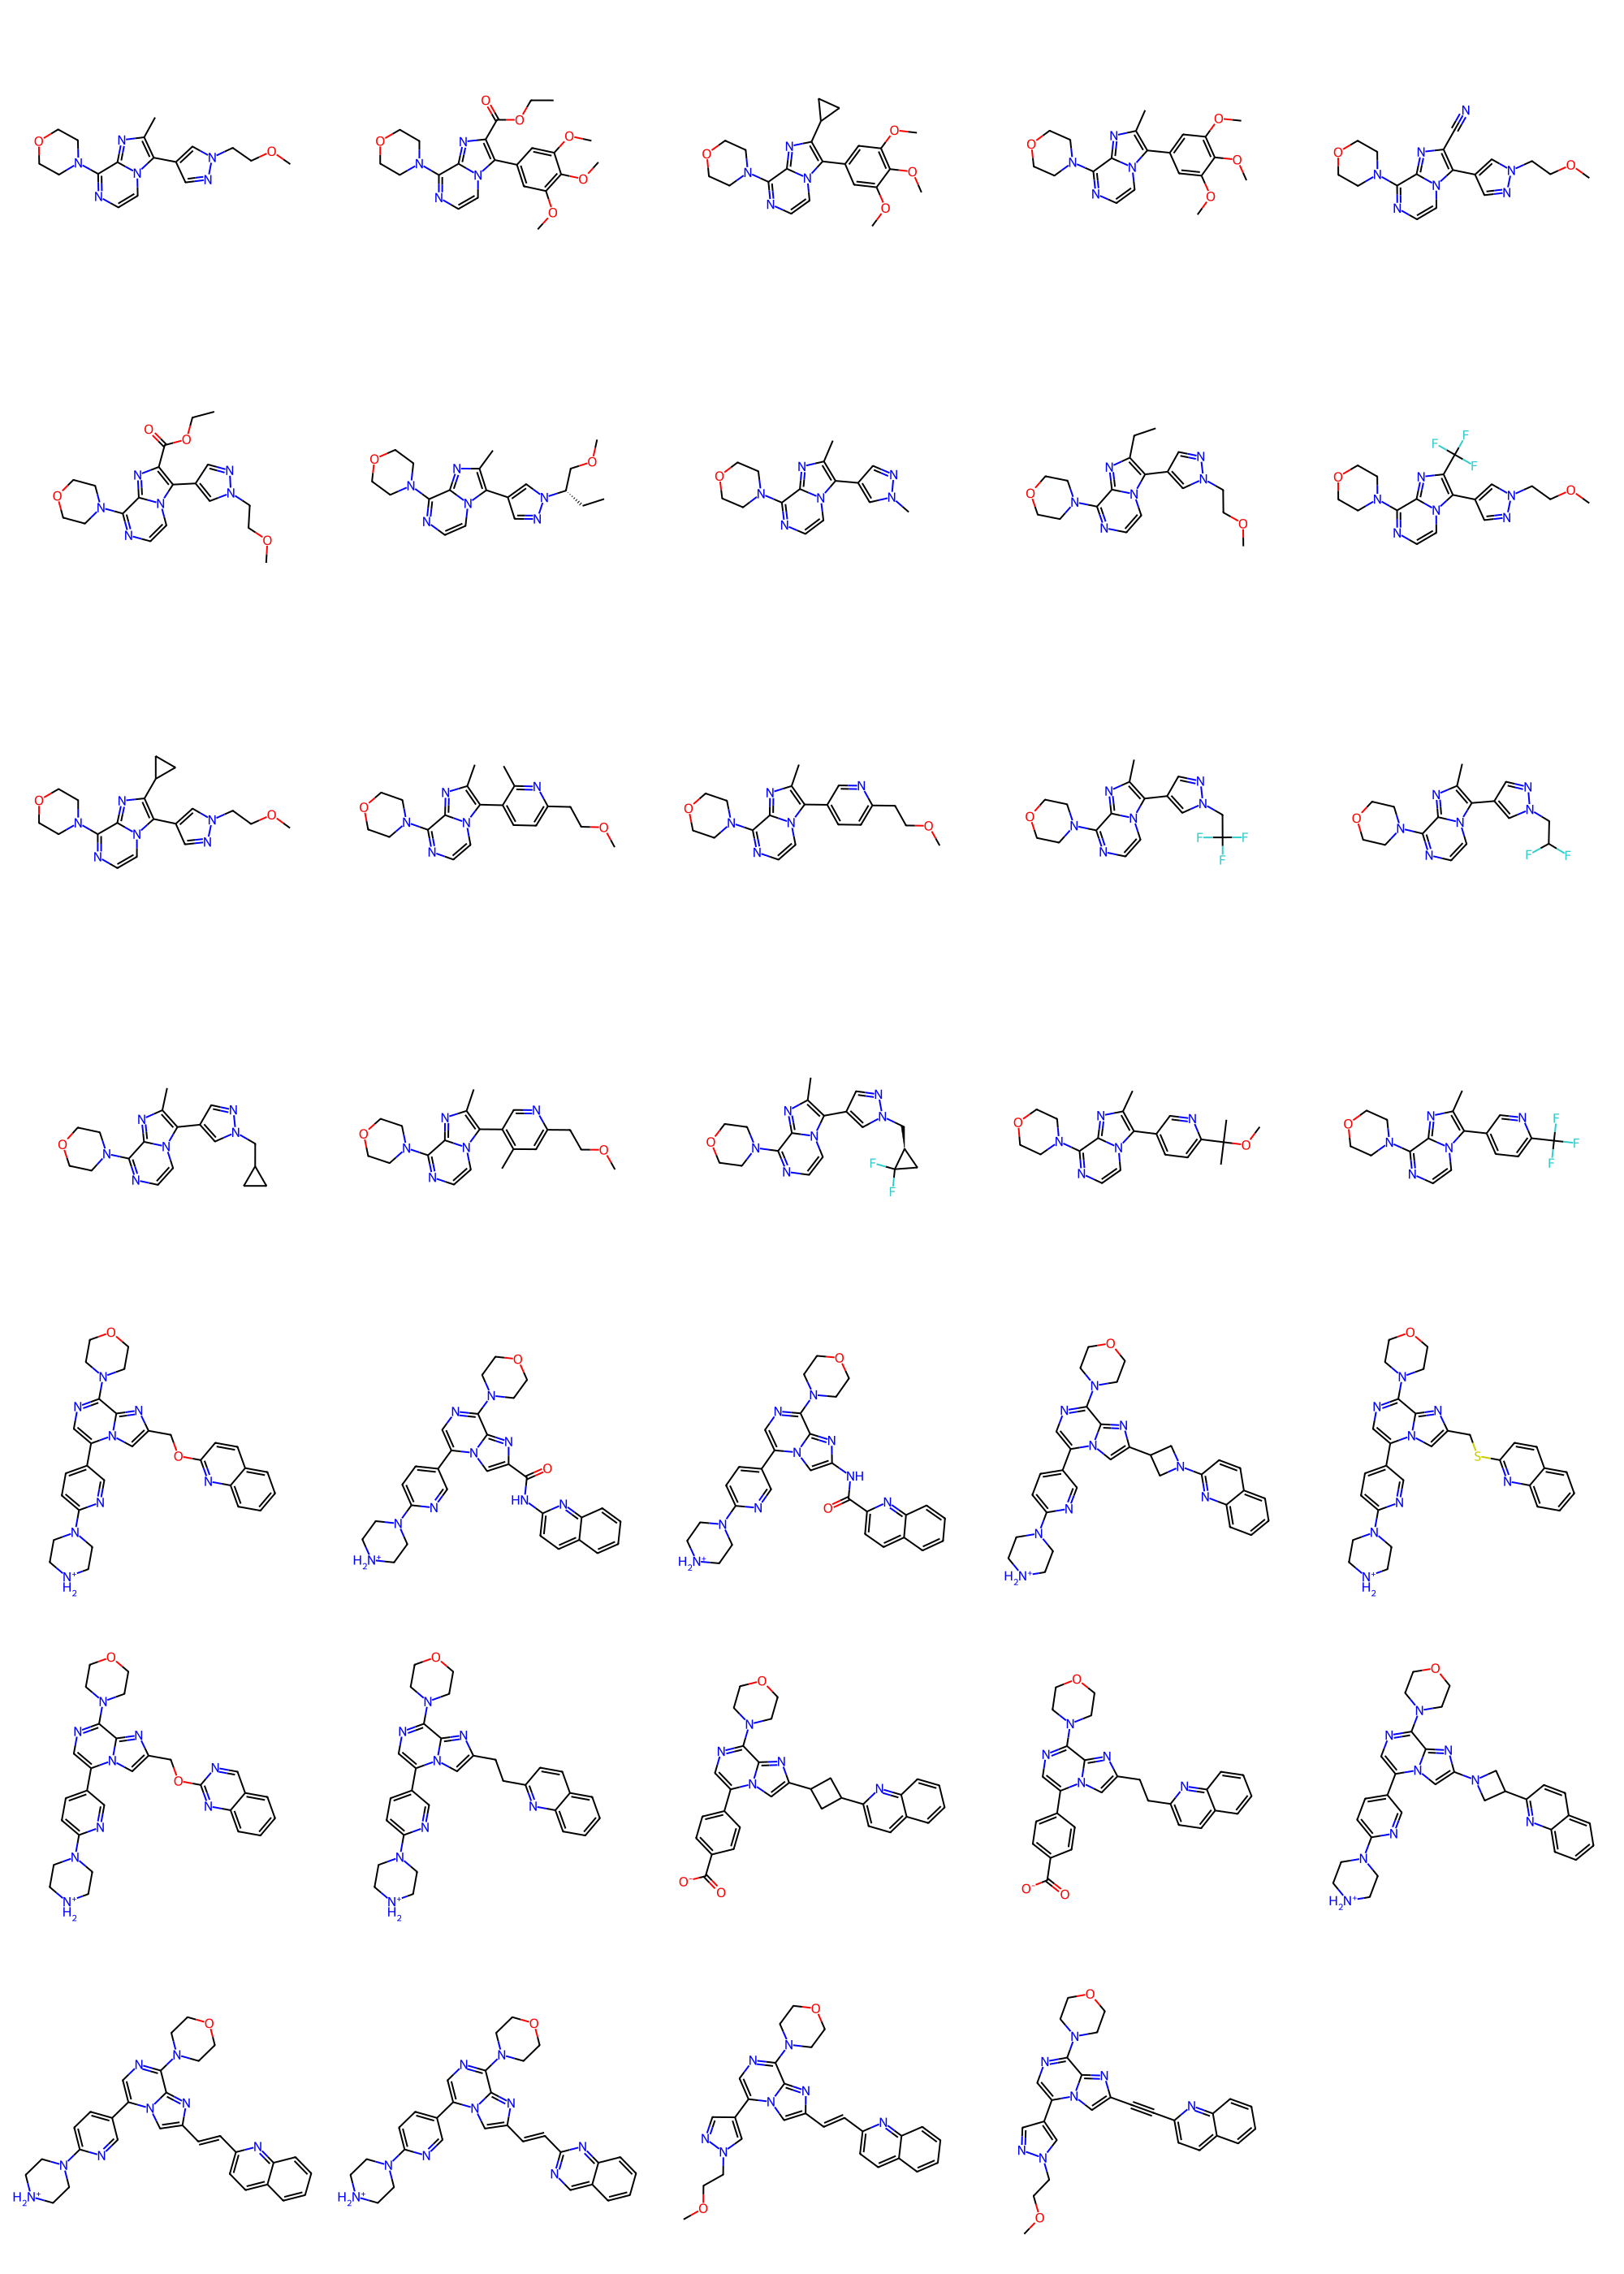

In [8]:
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display
import pandas as pd
from rdkit.Chem.Draw import rdMolDraw2D  # added for font config

# placeholders
mol_grid_per_row = 5      # molecules per row
sub_img_size = (400, 400) # (width, height) px

# configure atom-label font size
draw_opts = rdMolDraw2D.MolDrawOptions()
draw_opts.fixedFontSize = 16  # bigger atom labels

# load data
file_path = "../0_DATA/COMPOUNDS/0_MOLECULES.csv"
df = pd.read_csv(file_path)

# filter for pde10
pde10_df = df[df['target'].str.lower() == 'pde10']

# convert smiles → mols
mols = []
for smi in pde10_df['smiles']:
    mol = Chem.MolFromSmiles(smi)
    if mol:
        mols.append(mol)

# render grid (wrap into rows)
img = Draw.MolsToGridImage(
    mols,
    molsPerRow=mol_grid_per_row,
    subImgSize=sub_img_size,
    drawOptions=draw_opts,      # apply bigger font
    useSVG=False,
    returnPNG=False
)

# save & show
img.save("PDE10_MOLECULES.png")
display(img)
